<a href="https://colab.research.google.com/github/alyPoint/CEFET---Processamento-de-Sinais-I-140826/blob/main/Pratica_6/DSP_1_PRATICA_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Questão 1**

### **Letra a**

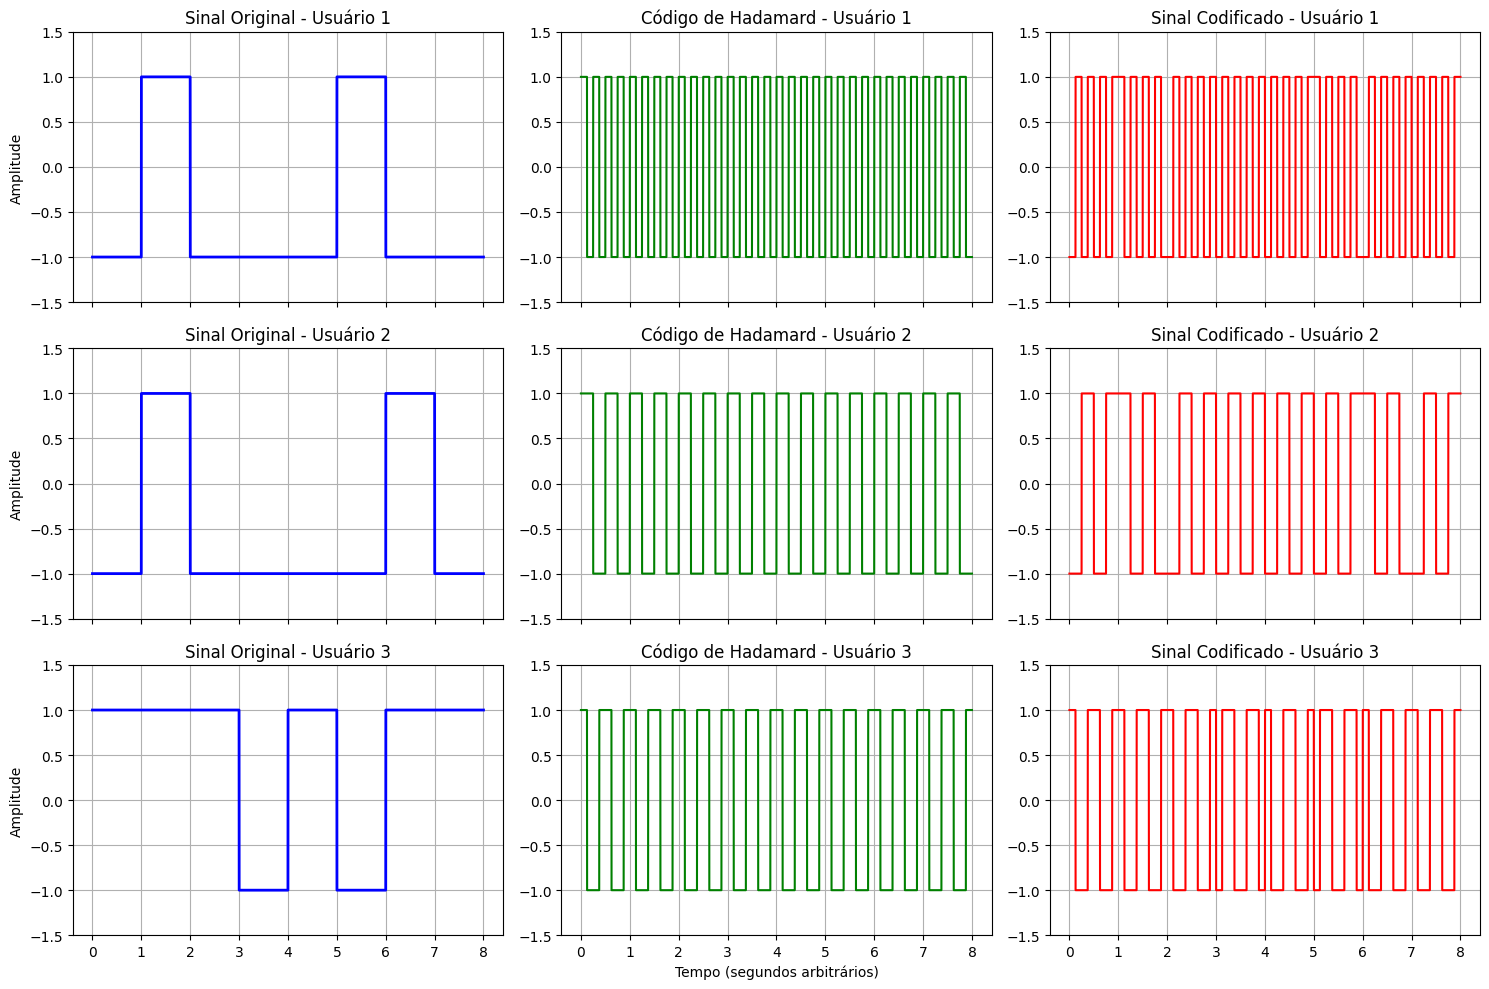

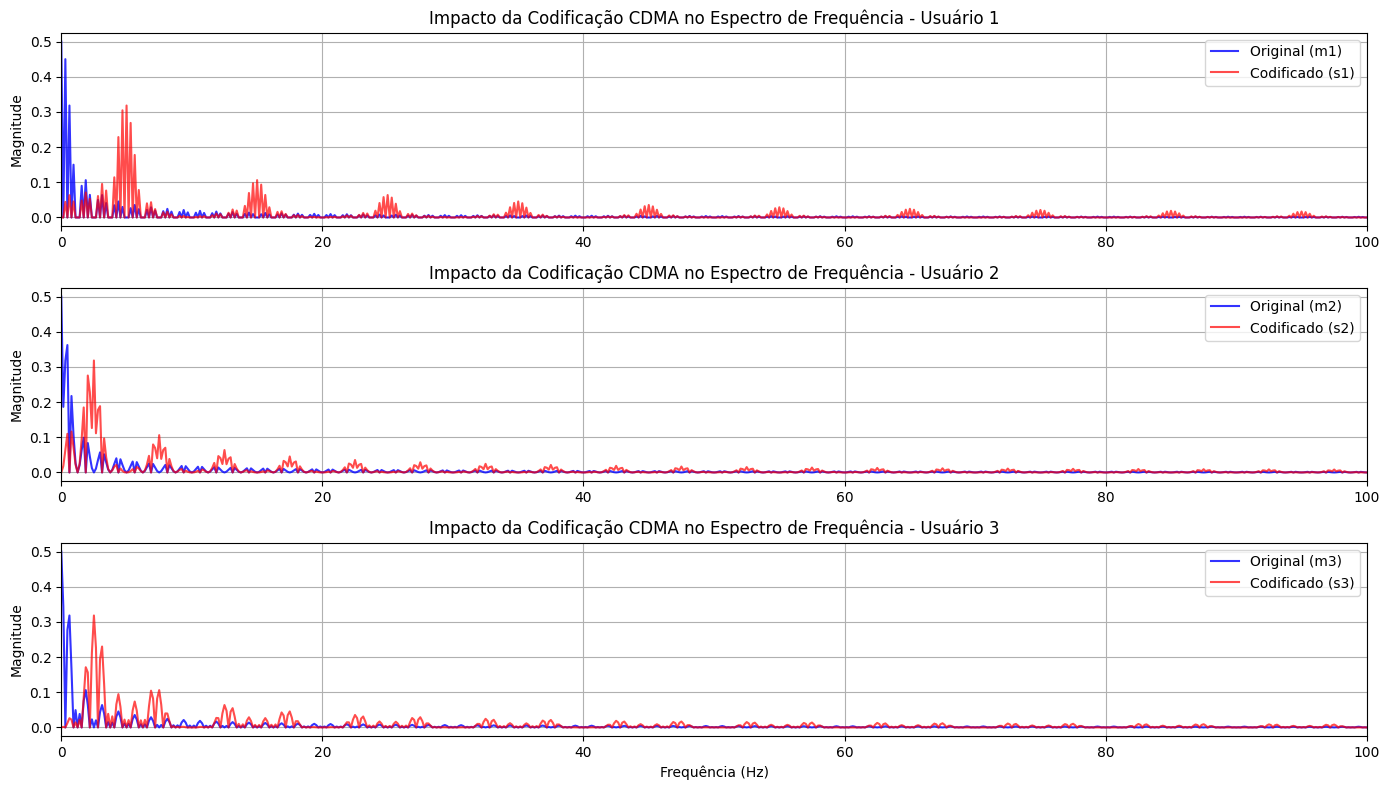

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard

# ==========================================
# 1. CONFIGURAÇÕES INICIAIS E GERAÇÃO DE DADOS
# ==========================================
np.random.seed(42)  # Semente para reprodutibilidade
N = 8               # Comprimento da sequência de bits e ordem da matriz de Hadamard
fs = 1000           # Frequência de amostragem para visualização do espectro (Hz)
samples_per_bit = 100  # Amostras por chip/bit para suavizar a forma de onda temporal

# Gerando mensagens originais m[n] em {-1, 1} de comprimento N=8 para 3 usuários
m1 = np.random.choice([-1, 1], N)
m2 = np.random.choice([-1, 1], N)
m3 = np.random.choice([-1, 1], N)

# ==========================================
# 2. GERAÇÃO DOS CÓDIGOS DE HADAMARD
# ==========================================
# A função hadamard(8) gera uma matriz 8x8 ortogonal
H = hadamard(N)
c1 = H[1, :]  # Código do Usuário 1 (Linha 1)
c2 = H[2, :]  # Código do Usuário 2 (Linha 2)
c3 = H[3, :]  # Código do Usuário 3 (Linha 3)

# ==========================================
# 3. CODIFICAÇÃO CDMA (ESPALHAMENTO ESPECTRAL)
# ==========================================
# O espalhamento é feito multiplicando cada bit do usuário pelo código de Hadamard completo.
# Alternativamente, pode ser visto como o produto kronecker ou expansão chip a chip.
s1 = np.kron(m1, c1)
s2 = np.kron(m2, c2)
s3 = np.kron(m3, c3)

# ==========================================
# 4. PREPARAÇÃO DOS SINAIS PARA GRÁFICOS TEMPORAIS
# ==========================================
# Para exibir os bits originais mantendo a duração total coerente com o sinal espalhado:
# Cada bit original possui N chips, logo sua duração visual deve abranger N * samples_per_bit por bit.
m1_upsampled = np.repeat(m1, N * samples_per_bit)
m2_upsampled = np.repeat(m2, N * samples_per_bit)
m3_upsampled = np.repeat(m3, N * samples_per_bit)

# Repetição dos códigos de Hadamard ao longo de todos os bits
c1_upsampled = np.tile(np.repeat(c1, samples_per_bit), N)
c2_upsampled = np.tile(np.repeat(c2, samples_per_bit), N)
c3_upsampled = np.tile(np.repeat(c3, samples_per_bit), N)

# Sinais espalhados (comprimento total = N * N chips)
s1_upsampled = np.repeat(s1, samples_per_bit)
s2_upsampled = np.repeat(s2, samples_per_bit)
s3_upsampled = np.repeat(s3, samples_per_bit)

# Vetor de tempo total
t = np.linspace(0, N, len(s1_upsampled))

# ==========================================
# 5. VISUALIZAÇÃO NO DOMÍNIO DO TEMPO (3 USUÁRIOS)
# ==========================================
fig, axs = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
signals = [
    (m1_upsampled, c1_upsampled, s1_upsampled, 'Usuário 1'),
    (m2_upsampled, c2_upsampled, s2_upsampled, 'Usuário 2'),
    (m3_upsampled, c3_upsampled, s3_upsampled, 'Usuário 3')
]

for i, (m, c, s, name) in enumerate(signals):
    # Sinal Original
    axs[i, 0].plot(t, m, 'b', linewidth=2)
    axs[i, 0].set_title(f'Sinal Original - {name}')
    axs[i, 0].grid(True)
    axs[i, 0].set_ylim(-1.5, 1.5)
    axs[i, 0].set_ylabel('Amplitude')

    # Código de Hadamard
    axs[i, 1].plot(t, c, 'g', linewidth=1.5)
    axs[i, 1].set_title(f'Código de Hadamard - {name}')
    axs[i, 1].grid(True)
    axs[i, 1].set_ylim(-1.5, 1.5)

    # Sinal Codificado (Espalhado)
    axs[i, 2].plot(t, s, 'r', linewidth=1.5)
    axs[i, 2].set_title(f'Sinal Codificado - {name}')
    axs[i, 2].grid(True)
    axs[i, 2].set_ylim(-1.5, 1.5)

axs[2, 1].set_xlabel('Tempo (segundos arbitrários)')
plt.tight_layout()
plt.show()

# ==========================================
# 6. CÁLCULO E VISUALIZAÇÃO DO ESPECTRO DE FREQUÊNCIA
# ==========================================
def calcular_espectro(sinal, fs):
    N_fft = len(sinal)
    freq = np.fft.fftfreq(N_fft, d=1/fs)
    espectro = np.abs(np.fft.fft(sinal)) / N_fft
    half = N_fft // 2
    return freq[:half], espectro[:half]

# Calculando para os 3 usuários
f_m1, E_m1 = calcular_espectro(m1_upsampled, fs)
f_s1, E_s1 = calcular_espectro(s1_upsampled, fs)

f_m2, E_m2 = calcular_espectro(m2_upsampled, fs)
f_s2, E_s2 = calcular_espectro(s2_upsampled, fs)

f_m3, E_m3 = calcular_espectro(m3_upsampled, fs)
f_s3, E_s3 = calcular_espectro(s3_upsampled, fs)

# Plotando os Espectros Comparativos
plt.figure(figsize=(14, 8))

plt.subplot(3, 1, 1)
plt.plot(f_m1, E_m1, 'b', label='Original (m1)', alpha=0.8)
plt.plot(f_s1, E_s1, 'r', label='Codificado (s1)', alpha=0.7)
plt.title('Impacto da Codificação CDMA no Espectro de Frequência - Usuário 1')
plt.ylabel('Magnitude')
plt.xlim(0, 100)
plt.legend(loc='upper right')
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(f_m2, E_m2, 'b', label='Original (m2)', alpha=0.8)
plt.plot(f_s2, E_s2, 'r', label='Codificado (s2)', alpha=0.7)
plt.title('Impacto da Codificação CDMA no Espectro de Frequência - Usuário 2')
plt.ylabel('Magnitude')
plt.xlim(0, 100)
plt.legend(loc='upper right')
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(f_m3, E_m3, 'b', label='Original (m3)', alpha=0.8)
plt.plot(f_s3, E_s3, 'r', label='Codificado (s3)', alpha=0.7)
plt.title('Impacto da Codificação CDMA no Espectro de Frequência - Usuário 3')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 100)
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

**Comentário sobre o Impacto da Codificação no Espectro do Sinal Espalhamento Espectral (Spread Spectrum):**

O sinal de dados original m[n] possui uma taxa de variação mais lenta (transições de bits espaçadas), o que concentra a maior parte da sua energia em frequências mais baixas (próximas a 0 Hz). Quando multiplicamos esse sinal pelo código de Hadamard c[n], que introduz variações de alta frequência (chips), ocorre a expansão da largura de banda do sinal no domínio da frequência.

---

**Redução da Densidade Espectral de Potência (DEP):**
Como a energia total do sinal é distribuída por uma faixa de frequências muito maior (devido aos chips de Hadamard de alta frequência), a magnitude espectral de pico do sinal codificado diminui consideravelmente em comparação ao sinal original. Isso torna o sinal CDMA mais resistente a interferências de banda estreita e confere propriedades de espalhamento semelhantes a ruído (baixo perfil de interceptação).

---

**Ortogonalidade:**
Como as linhas da matriz de Hadamard formam um conjunto de códigos perfeitamente ortogonais entre si, os três usuários podem ocupar exatamente a mesma faixa de frequência e o mesmo intervalo de tempo simultaneamente sem sofrer interferência mútua no receptor, desde que a des-espalhamento seja feito com o respectivo código correto.

### **Letra b**

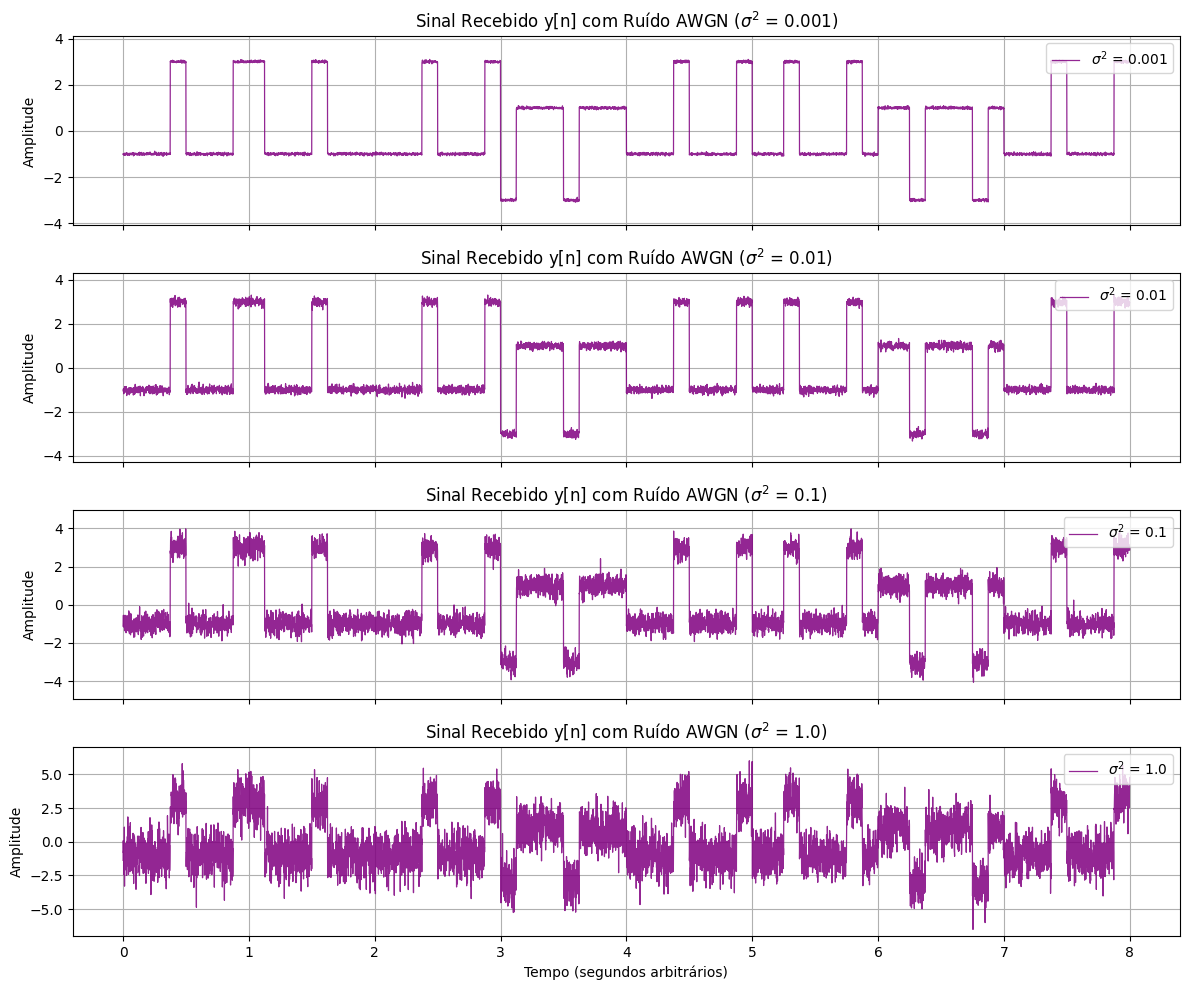

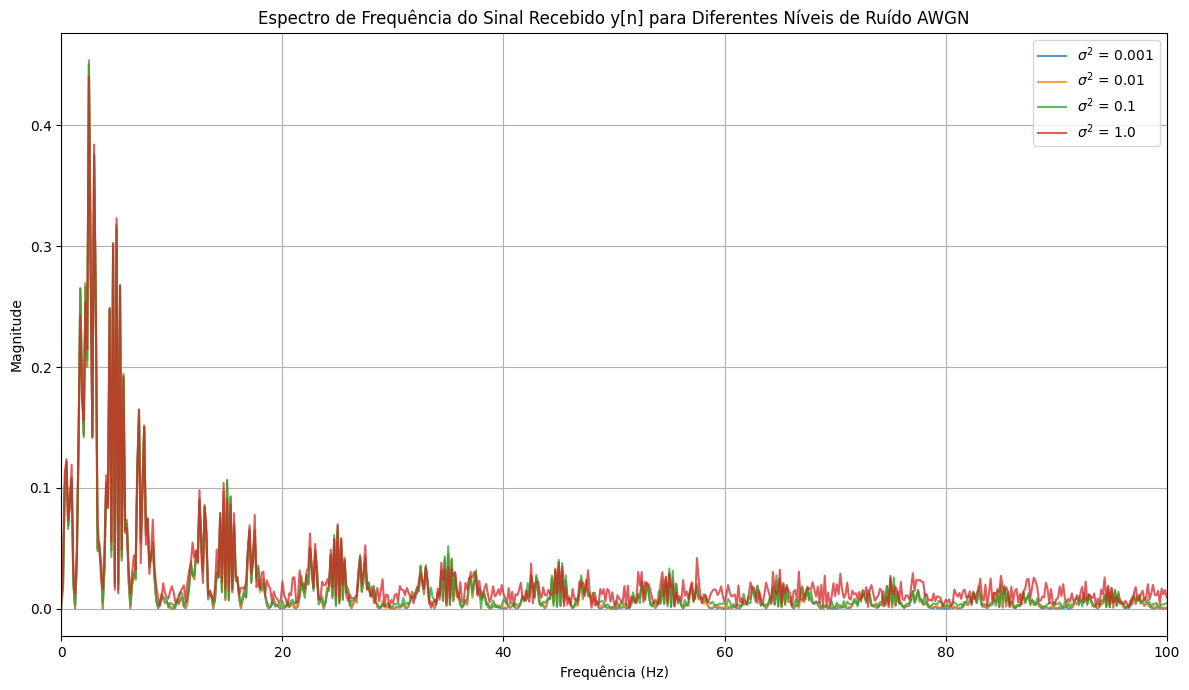

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard

# ==========================================
# 1. RECONSTRUÇÃO DOS SINAIS DOS USUÁRIOS
# ==========================================
np.random.seed(42)  # Mesma semente para garantir consistência
N = 8
fs = 1000
samples_per_bit = 100

# Mensagens originais
m1 = np.random.choice([-1, 1], N)
m2 = np.random.choice([-1, 1], N)
m3 = np.random.choice([-1, 1], N)

# Matriz de Hadamard e Códigos
H = hadamard(N)
c1 = H[1, :]
c2 = H[2, :]
c3 = H[3, :]

# Sinais codificados (espalhados)
s1 = np.kron(m1, c1)
s2 = np.kron(m2, c2)
s3 = np.kron(m3, c3)

# Formas de onda upsampled (contínuas por partes)
s1_upsampled = np.repeat(s1, samples_per_bit)
s2_upsampled = np.repeat(s2, samples_per_bit)
s3_upsampled = np.repeat(s3, samples_per_bit)

# Sinal combinado dos 3 usuários (sem ruído)
x_sum = s1_upsampled + s2_upsampled + s3_upsampled
t = np.linspace(0, N, len(x_sum))

# Variâncias do ruído AWGN a serem avaliadas
sigma_sq_list = [1e-3, 1e-2, 1e-1, 1.0]

# ==========================================
# 2. VISUALIZAÇÃO NO DOMÍNIO DO TEMPO
# ==========================================
fig, axs = plt.subplots(len(sigma_sq_list), 1, figsize=(12, 10), sharex=True)

for i, sigma_sq in enumerate(sigma_sq_list):
    sigma = np.sqrt(sigma_sq)
    # Geração do ruído AWGN w[n] ~ N(0, sigma^2)
    w = np.random.normal(0, sigma, size=len(x_sum))

    # Sinal recebido y[n]
    y = x_sum + w

    axs[i].plot(t, y, color='purple', linewidth=0.9, alpha=0.85, label=f'$\\sigma^2$ = {sigma_sq}')
    axs[i].set_title(f'Sinal Recebido y[n] com Ruído AWGN ($\\sigma^2$ = {sigma_sq})')
    axs[i].set_ylabel('Amplitude')
    axs[i].grid(True)
    axs[i].legend(loc='upper right')
    axs[i].set_ylim(-4 - 3*sigma, 4 + 3*sigma)

axs[-1].set_xlabel('Tempo (segundos arbitrários)')
plt.tight_layout()
plt.show()

# ==========================================
# 3. CÁLCULO E VISUALIZAÇÃO DO ESPECTRO DE y[n]
# ==========================================
def calcular_espectro(sinal, fs):
    N_fft = len(sinal)
    freq = np.fft.fftfreq(N_fft, d=1/fs)
    espectro = np.abs(np.fft.fft(sinal)) / N_fft
    half = N_fft // 2
    return freq[:half], espectro[:half]

plt.figure(figsize=(12, 7))

for sigma_sq in sigma_sq_list:
    sigma = np.sqrt(sigma_sq)
    w = np.random.normal(0, sigma, size=len(x_sum))
    y = x_sum + w

    freqs, espectro = calcular_espectro(y, fs)
    plt.plot(freqs, espectro, alpha=0.75, label=f'$\\sigma^2$ = {sigma_sq}')

plt.title('Espectro de Frequência do Sinal Recebido y[n] para Diferentes Níveis de Ruído AWGN')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 100)
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()

### **Comentários sobre o Impacto de $\sigma^2$**
1. **Domínio do Tempo:**
- Baixa Variância ($\sigma^2 = 10^{-3}$ e $10^{-2}$): O ruído é quase
imperceptível. A forma de onda combinada dos três usuários ($x_1 + x_2 + x_3$) permanece nítida, com transições bem definidas e amplitudes que refletem a sobreposição construtiva/destrutiva dos chips de Hadamard.
- Alta Variância ($\sigma^2 = 1$): O ruído gaussiano domina visualmente a forma de onda. As transições dos bits e chips ficam severamente distorcidas e mascaradas pelas flutuações estocásticas de alta amplitude, o que exigirá o processo de correlação (des-espalhamento) no receptor para recuperar os dados originais.

#-----------------------------------------------------------------------------------

2. Espectro de Frequência:
- Elevação do Piso de Ruído (Noise Floor): Como o ruído AWGN possui uma densidade espectral de potência plana (branco) em todas as frequências, o aumento de $\sigma^2$ eleva de maneira uniforme a magnitude do piso de ruído em todo o espectro.
- Mascaramento Espectral: Para $\sigma^2 = 1$, o nível do ruído se torna comparável ou superior às componentes espectrais do sinal útil, dificultando a identificação visual das características de banda dos sinais espalhados e degradando a relação sinal-ruído (SNR) do canal.

### **Letra d**

### **Letra f**

## **Questão 2**

## **Questão 3**

### **Letra b**

### **Letra c**

## **Questão 4**

### **Letra a**

### **Letra b**

### **Letra c**

### **Letra d**

### **Letra e**